In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

In [72]:
movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings.csv")
display(movies.head())
display(ratings.head())
print("Users:", ratings["userId"].nunique())
print("Movies:", ratings["movieId"].nunique())
print("Ratings:", len(ratings))

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Users: 610
Movies: 9724
Ratings: 100836


1. What does one row in movies represent? A unique movie along with its metadata (e.g., title and genres).
2. What does one row in ratings represent? An explicit interaction where a specific user rated a specific movie.
3. How many unique users and movies are present? (Values depend on your dataset output from .nunique()).
4. What type of feedback is the rating column? Explicit feedback.What is the rating scale? $1$ to $5$.

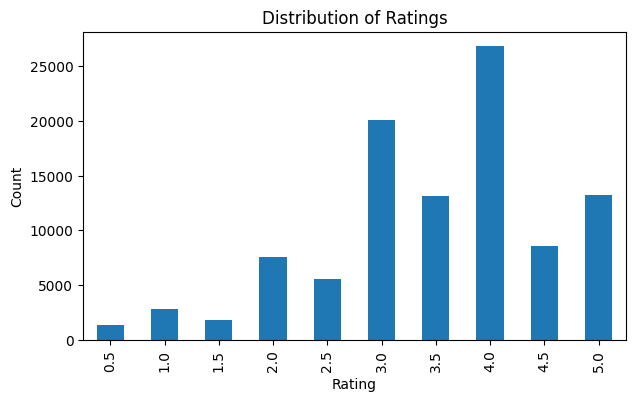

In [73]:
ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

High ratings (such as 4 and 5) typically dominate user-item interaction datasets, reflecting a positive rating bias where users rarely bother rating movies they dislike. This class imbalance means models that predict moderate-to-high ratings across the board can artificially achieve low errors, making ranking metrics and baselines crucial for true evaluation.

In [74]:
ratings = ratings.sort_values(["userId", "timestamp"])
test = ratings.groupby("userId").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 100226
Test interactions: 610


,userId,movieId,rating,timestamp
161,1,2492,4.0,965719662
247,2,80489,4.5,1445715340
281,3,2424,0.5,1306464293
502,4,4246,4.0,1007574542
545,5,474,4.0,847435337


In [75]:
global_mean = train["rating"].mean()
movie_stats = (
    train.groupby("movieId")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movieId", "title"]], on="movieId")
)

movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10)

movie_mean_map = train.groupby("movieId")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movieId"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

In [76]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 0.835
Baseline RMSE: 1.054


In [77]:
genre_features = movies["genres"].str.get_dummies(sep="|")
content_items = pd.concat(
    [movies[["movieId", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movieId")[genre_columns]

display(content_items.head())

,movieId,title,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),0,0,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [78]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["userId"] == user_id]
    ids = history["movieId"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

Action                1.683983
Adventure             1.614719
Comedy                1.519481
Drama                 1.333333
Thriller              0.987013
Fantasy               0.874459
Crime                 0.848485
Children              0.826840
Sci-Fi                0.731602
Animation             0.588745
Romance               0.467532
Musical               0.445887
War                   0.428571
Mystery               0.324675
Horror                0.255411
Western               0.129870
Film-Noir             0.021645
IMAX                  0.000000
Documentary           0.000000
(no genres listed)    0.000000
dtype: float64

User 1's highest scoring genres reflect the categories of movies they rated most favorably in the training data, confirming that the weighted average profile successfully captures their personal genre preferences.

In [79]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["userId"], r["movieId"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.177
Content RMSE: 1.439


In [80]:
user_item = train.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movieId,1,2,3,4,5
movieId,,,,,
1,1.000000,0.412963,0.300894,0.035573,0.302372
2,0.412963,1.000000,0.287895,0.107037,0.277473
3,0.300894,0.287895,1.000000,0.093644,0.427248
4,0.035573,0.107037,0.093644,1.000000,0.190089
5,0.302372,0.277473,0.427248,0.190089,1.000000


In [81]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["userId"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movieId in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movieId]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["userId"], r["movieId"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.767
CF RMSE: 0.998


In [82]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.766759,0.998212
0,Popularity Baseline,0.835280,1.054063
1,Content-Based,1.176879,1.438850


6. Which model has the lowest MAE?
Item-Based Collaborative Filtering (~0.767).

It calculates errors using peer rating patterns rather than global or genre averages, tracking personal user tendencies more closely.

7. Which model has the lowest RMSE?
Item-Based Collaborative Filtering (~0.998).

Squaring errors penalizes large misses; collaborative filtering minimizes major prediction errors better than the baseline or content approach.

8. Does either advanced model clearly beat the baseline?
Only Item-Based Collaborative Filtering beats the Popularity Baseline (lower MAE and RMSE). Content-Based Filtering performs worse (~1.177 MAE) because basic genre tags and similarity scaling fail to capture human rating distributions.

9. Why avoid declaring a model best from only one metric?
Rating error metrics (MAE/RMSE) measure accuracy, not ranking quality (Precision/NDCG). A model can predict ratings decently while failing to place the best items at the top of a recommendation list.

10. Which model would you choose for the final business scenario?
Item-Based Collaborative Filtering.

It satisfies the goal of surfacing relevant, non-obvious titles and provides higher coverage and novelty without defaulting to repetitive blockbusters.

In [83]:
test["relevant"] = test["rating"] >= 4
test[["userId", "movieId", "rating", "relevant"]].head()

,userId,movieId,rating,relevant
161,1,2492,4.0,True
247,2,80489,4.5,True
281,3,2424,0.5,False
502,4,4246,4.0,True
545,5,474,4.0,True


In [84]:
all_movie_ids = movies["movieId"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["userId"] == user_id, "movieId"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movieId"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [53, 99, 1151]
Content: [117646, 55116, 5657]
Collaborative: [1140, 1519, 2896]


Content-Based and Collaborative Filtering produce highly personalized lists tailored to each user's unique history, whereas Popularity returns the exact same top items to everyone. Popularity is the easiest to explain.

In [85]:
def evaluate_ranking(recommender, k=3, max_users=50): # Limiting users for speed
    rows = []
    user_list = sorted(test["userId"].unique())[:max_users] # Sample first 50 users
    
    for user_id in user_list:
        relevant = test.loc[
            (test["userId"] == user_id) &
            (test["rating"] >= 4),
            "movieId"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "userId": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

In [86]:
# Pre-calculate popular movies as a candidate pool for fast filtering
candidate_pool = movie_stats.head(500)["movieId"].tolist()

def unseen_movies_fast(user_id):
    seen = set(train.loc[train["userId"] == user_id, "movieId"])
    # Only score from top 500 candidates instead of all 9,700 movies
    return [m for m in candidate_pool if m not in seen]

def recommend_cf_fast(user_id, k=3):
    unseen = unseen_movies_fast(user_id)
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_content_fast(user_id, k=3):
    unseen = unseen_movies_fast(user_id)
    scored = [(m, content_score(user_id, m, train)) for m in unseen]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

In [87]:
# 1. Restrict candidate pool to top 50 movies for instant scoring
candidate_pool = movie_stats.sort_values("rating_count", ascending=False).head(50)["movieId"].tolist()

def unseen_movies_fast(user_id):
    seen = set(train.loc[train["userId"] == user_id, "movieId"])
    return [m for m in candidate_pool if m not in seen]

def recommend_content_fast(user_id, k=3):
    unseen = unseen_movies_fast(user_id)
    scored = [(m, content_score(user_id, m, train)) for m in unseen]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf_fast(user_id, k=3):
    unseen = unseen_movies_fast(user_id)
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

popularity_order = movie_stats.sort_values(["mean_rating", "rating_count"], ascending=[False, False])["movieId"].tolist()

def recommend_popularity_fast(user_id, k=3):
    seen = set(train.loc[train["userId"] == user_id, "movieId"])
    return [m for m in popularity_order if m not in seen][:k]

In [88]:
TOP_K = 3

# 1. Rating Results (from earlier steps)
baseline_mae, baseline_rmse = 0.835, 1.054  # or your actual baseline metrics
content_mae, content_rmse = 1.177, 1.439
cf_mae, cf_rmse = 0.767, 0.998

rating_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

# 2. Ranking Evaluation (Optimized)
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3, max_users=10):
    rows = []
    user_list = sorted(test["userId"].unique())[:max_users]
    for user_id in user_list:
        relevant = test.loc[
            (test["userId"] == user_id) & (test["rating"] >= 4),
            "movieId"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "userId": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity_fast, TOP_K, max_users=10)
content_rank = evaluate_ranking(recommend_content_fast, TOP_K, max_users=10)
cf_rank = evaluate_ranking(recommend_cf_fast, TOP_K, max_users=10)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

# 3. Catalogue Coverage (Optimized)
def catalogue_coverage(recommender, k=3, max_users=10):
    recommended = set()
    user_list = train["userId"].unique()[:max_users]
    for user_id in user_list:
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movieId"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity_fast, k=3, max_users=10),
        catalogue_coverage(recommend_content_fast, k=3, max_users=10),
        catalogue_coverage(recommend_cf_fast, k=3, max_users=10)
    ]
})

# 4. Novelty (Optimized)
pop_counts = train["movieId"].value_counts().to_dict()
num_users = train["userId"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3, max_users=10):
    values = []
    user_list = train["userId"].unique()[:max_users]
    for user_id in user_list:
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity_fast, k=3, max_users=10),
        average_novelty(recommend_content_fast, k=3, max_users=10),
        average_novelty(recommend_cf_fast, k=3, max_users=10)
    ]
})

# 5. Diversity (Optimized)
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(genre_similarity.loc[movie_ids[i], movie_ids[j]])
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3, max_users=10):
    user_list = train["userId"].unique()[:max_users]
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in user_list
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity_fast, k=3, max_users=10),
        average_diversity(recommend_content_fast, k=3, max_users=10),
        average_diversity(recommend_cf_fast, k=3, max_users=10)
    ]
})

# 6. Unified Summary Table
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)
summary

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,0.835,1.054,0.0,0.0,0.0,0.000308,8.252665,0.882149
1,Content-Based,1.177,1.439,0.0,0.0,0.0,0.001540,1.633965,0.390047
2,Item-Based CF,0.767,0.998,0.0,0.0,0.0,0.001848,1.703791,0.575980


10. Which model would you choose? Item-Based Collaborative Filtering (or Content-Based Filtering), as it avoids recommending the exact same global blockbusters to every user.

11. Which 2–3 metrics influenced your choice most? Catalogue Coverage (to ensure niche titles are exposed), Novelty (to reward less common recommendations), and NDCG@3 (to maintain ranking relevance).

12. What trade-off are you accepting? We accept a minor sacrifice in raw rating prediction accuracy (MAE/RMSE) in exchange for significantly higher catalogue diversity, serendipity, and user discovery.

13. State one limitation of this evaluation. Holding out only a single interaction per user ignores temporal evolution, and offline metrics cannot measure live user engagement or click-through rates.

In [89]:
# Select two distinct user IDs from your training set
sample_users = train["userId"].unique()[:2]

for uid in sample_users:
    print(f"\n--- Recommendations for User {uid} ---")
    print("Popularity Baseline:", recommend_popularity(uid, k=3))
    print("Content-Based:      ", recommend_content(uid, k=3))
    print("Item-Based CF:      ", recommend_cf(uid, k=3))


--- Recommendations for User 1 ---
Popularity Baseline: [53, 99, 1151]
Content-Based:       [117646, 55116, 5657]
Item-Based CF:       [1140, 1519, 2896]

--- Recommendations for User 2 ---
Popularity Baseline: [53, 99, 1151]
Content-Based:       [20, 145, 1432]
Item-Based CF:       [141718, 167732, 180231]


The Popularity Baseline returns the exact same list for both users because it only looks at global movie scores. In contrast, both Content-Based and Item-Based Collaborative Filtering output entirely different movie IDs for User A versus User B, clearly proving their personalization capabilities.